# **Project 2: 2-Node Network Reduction**

**Instructions:**

- Identify a large 2-node network dataset—you can start with a dataset in a repository.  Your data should meet the criteria that it consists of ties between and not within two (or more) distinct groups.
- Reduce the size of the network using a method such as the island method described in chapter 4 of social network analysis.
- What can you infer about each of the distinct groups?


Name: Guillermo Schneider <br>
Dataset: Social Network: MOOC (Massive Open Online Course) User Action Dataset <br>
Link: https://snap.stanford.edu/data/act-mooc.html

Dataset Description: The MOOC (Massive Open Online Course) user action dataset represents the actions taken by users on a popular MOOC platform. The actions are represented as a directed, temporal network. The nodes represent users and course activities (targets), and edges represent the actions by users on the targets. Users (Node), Course Activities (Node), and Actions on Activities (Edges).

In [1]:
import networkx as nx
import pandas as pd
from networkx.algorithms import bipartite
import matplotlib.pyplot as plt
from itertools import combinations
import numpy as np
import math
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

In [2]:
#tsv file with ACTIONID	USERID	TARGETID as the column names
df = pd.read_csv("mooc_actions.tsv", sep="\t")

#tsv file with ACTIONID	LABEL as the column names, a binary label indicating whether the student drops-out after the action. 
#The value is 1 for drop-out actions, 0 otherwise.
labels = pd.read_csv("mooc_action_labels.tsv", sep="\t")

In [3]:
#new empty graph
G = nx.Graph()

In [4]:
# Add user-target edges, preserving ACTIONID as an edge attribute
for row in df.itertuples(index=False):
    G.add_edge(
        ("user", row.USERID),
        ("target", row.TARGETID),
        actionid=row.ACTIONID
    )

# Mark the two node partitions
nx.set_node_attributes(
    G,
    {
        n: 0 if n[0] == "user" else 1
        for n in G.nodes
    },
    "bipartite"
)

In [5]:
# Create ACTIONID -> LABEL mapping
label_map = labels.set_index("ACTIONID")["LABEL"].to_dict()

for row in df.itertuples(index=False):
    u = ("user", row.USERID)
    v = ("target", row.TARGETID)

    if row.ACTIONID in label_map and G.has_edge(u, v):
        G[u][v]["LABEL"] = label_map[row.ACTIONID]

In [6]:
#user id, class id, action id, and binary drop out LABEL actionid attribute (1 for drop-out)
for edge in list(G.edges(data=True))[:10]:
    print(edge)

(('user', 0), ('target', 0), {'actionid': 12, 'LABEL': 0})
(('user', 0), ('target', 1), {'actionid': 4945, 'LABEL': 0})
(('user', 0), ('target', 2), {'actionid': 14, 'LABEL': 0})
(('user', 0), ('target', 3), {'actionid': 102005, 'LABEL': 0})
(('user', 0), ('target', 4), {'actionid': 9935, 'LABEL': 0})
(('user', 0), ('target', 5), {'actionid': 78352, 'LABEL': 0})
(('user', 0), ('target', 6), {'actionid': 102006, 'LABEL': 0})
(('user', 0), ('target', 7), {'actionid': 87353, 'LABEL': 0})
(('user', 0), ('target', 8), {'actionid': 104829, 'LABEL': 0})
(('user', 0), ('target', 9), {'actionid': 13, 'LABEL': 0})


### **EDA**

In [7]:
#7144 nodes, both users and classes
G.number_of_nodes()

7144

In [8]:
#split into bottom and top 
users, classes = bipartite.sets(G)
#primary or top set is considered more responsible for tie creation. Users
nodes_in_users = len(users)        
#rather than the secondary or bottom node set. Classes
nodes_in_classes = len(classes) 

In [9]:
#7047 users
nodes_in_users

7047

In [10]:
#97 classes 
nodes_in_classes

97

In [11]:
#178,443 actions by users on the classes
G.number_of_edges()

178443

In [58]:
#4066 actions the user dropped-out of the course after this action. 
#this seems low for 7000 users, 97 classes, and 178,000 actions, but maybe theyre commited students
#i think theyre probably just counting a "dropped out" action, rather than just "inactive" in the class?
dropped_out_count = sum(1 for _, _, attrs in G.edges(data=True) if attrs.get("LABEL") == 1)
print("Number of edges with LABEL (dropped out) = 1:", dropped_out_count)

Number of edges with LABEL (dropped out) = 1: 4066


In [13]:
nx.is_bipartite(G)

True

In [14]:
#number of connections (degree) for each user
user_nodes = {n for n, d in G.nodes(data=True) if d["bipartite"] == 0} #grab just the user nodes
user_degrees = [G.degree(user) for user in user_nodes]

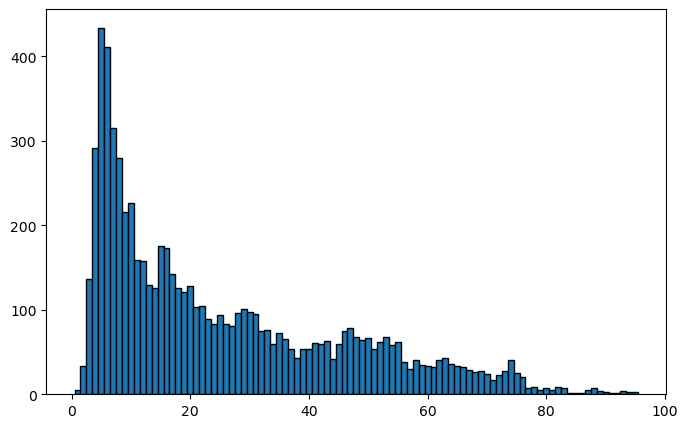

In [15]:
# histogram
plt.figure(figsize=(8, 5))
plt.hist(
    user_degrees, bins=range(min(user_degrees), max(user_degrees) + 2), edgecolor="black", align="left"
)
plt.show()

The majority of users interact just a few times (<10) with course activities on the MOOC website. But there are some users who interacted up to 100 times.

The majority of Classes have few actions (<1000 actions) taken on them as well, but it seems there are some popular ones as well up to 6000 actions. With 7047 users, i kinda expected more average actions per class? But I guess it makes sense that not all ~7000 users ever took the same class, its just a portion of those users for each class, doing many actions.

In [16]:
#number of connections (degree) for each class
class_nodes = {n for n, d in G.nodes(data=True) if d["bipartite"] == 1} #grab just the class nodes
class_degrees = [G.degree(target) for target in class_nodes]

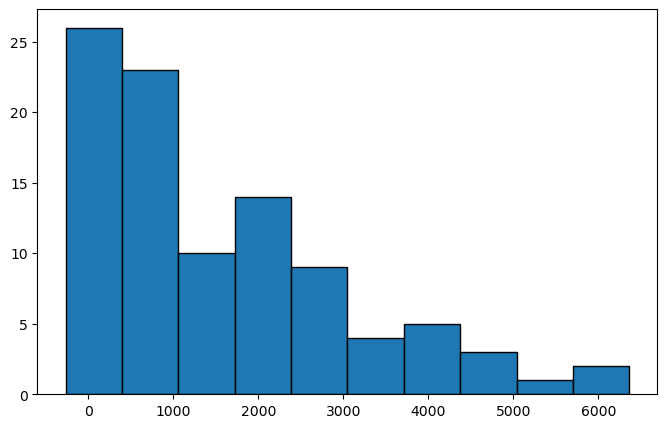

In [17]:
# histogram
plt.figure(figsize=(8, 5))
plt.hist(
    class_degrees, edgecolor="black", align="left"
)
plt.show()

In [18]:
#our top 10 users by number of actions. 
top_10_users_actions = sorted(
    (
        (user_id, G.degree(("user", user_id)))
        for node_type, user_id in G.nodes()
        if node_type == "user"
    ),
    key=lambda x: x[1],
    reverse=True
)[:10]

for user_id, num_actions in top_10_users_actions:
    print(f"User {user_id}: {num_actions} actions")

User 317: 95 actions
User 796: 95 actions
User 824: 95 actions
User 2243: 94 actions
User 4982: 94 actions
User 6371: 94 actions
User 79: 93 actions
User 205: 93 actions
User 1515: 93 actions
User 4102: 93 actions


The top classes are all low id numbers <15 (there are 97 classes), i wonder if this is just a coincidence or if these classes were the earliest to premier on the MOOC's website.

In [19]:
#our top 10 classes by number of actions. 
top_10_users_actions = sorted(
    (
        (target_id, G.degree(("target", target_id)))
        for node_type, target_id in G.nodes()
        if node_type == "target"
    ),
    key=lambda x: x[1],
    reverse=True
)[:10]

for target_id, num_actions in top_10_users_actions:
    print(f"Class {target_id}: {num_actions} actions")

Class 1: 6695 actions
Class 3: 6159 actions
Class 4: 5579 actions
Class 7: 5207 actions
Class 8: 5015 actions
Class 5: 4948 actions
Class 9: 4609 actions
Class 14: 4549 actions
Class 13: 4395 actions
Class 6: 4283 actions


### **Island Method**

In [27]:
#I tried using the weighted project graph method on user nodes originally but it the whole process kept hanging, i couldnt get it to finish
#I think its because we have so many edges connected to so many interconnected users and classes? so it creates a really huge hairball network?
#i used class nodes instead b/c there are less of them and it actually would run
B = bipartite.weighted_projected_graph(G, class_nodes)

Bipartite projection must explicitly preserve or calculate LABEL when creating projected edges. NetworkX does not automatically transfer arbitrary edge attributes during projection. Projected edge's Drop Out LABEL is now the number of shared neighbour classes connected through edges labelled 1 (drop out) where a user dropped out of either class. I originally tried to set it to where a user dropped out of both classes, we would keep the drop out label but almost no classes had shared users dropping out

In [29]:
#Adding back LABEL (drop out)

for u, v in B.edges():

    # Find shared neighbours in original bipartite graph
    shared = set(G[u]) & set(G[v])

    # Count shared neighbours if either of original edges have LABEL=1
    label_count = sum(
        1
        for neighbour in shared
        if G[u][neighbour].get('LABEL') == 1
        or G[v][neighbour].get('LABEL') == 1
    )

    B[u][v]['LABEL'] = label_count

In [28]:
#All the classes are originally connected, there are no isolated or disconnected groups
all_islands = list(nx.connected_components(B))

island_sizes = sorted(
    [len(island) for island in all_islands],
    reverse=True
)

print("Number of islands:", len(island_sizes))
print("Island sizes:", island_sizes)

Number of islands: 1
Island sizes: [97]


Function to virtually raise the water level. The function below takes a graph, and applies a threshold (“water
level”), letting all edges above a certain value through, and removing all others. We're using "user count" as the threshold.

In [30]:
#Remove edges whose weight is less than or equal to the threshold.
def trim_edges(g, weight=1):
    g2 = nx.Graph()

    # Preserve isolated nodes
    g2.add_nodes_from(g.nodes(data=True))

    for u, v, edata in g.edges(data=True):
        if edata.get('weight', 1) > weight:
            g2.add_edge(u, v, **edata)

    return g2

Defining how the water level should be raised. We will compute evenly spaced thresholds and produce a list of networks at each water level:

In [31]:
#Generate networks with progressively higher edge-weight thresholds
def island_method(g, iterations=5):

    weights = [
        edata['weight']
        for _, _, edata in g.edges(data=True)
        if 'weight' in edata
    ]

    if not weights:
        raise ValueError("Graph contains no weighted edges.")

    mn = int(min(weights))
    mx = int(max(weights))

    if iterations < 1:
        raise ValueError("iterations must be at least 1.")

    # Generate thresholds without a zero step
    thresholds = [
        mn + (mx - mn) * i / iterations
        for i in range(iterations)
    ]

    return [
        [threshold, trim_edges(g, threshold)]
        for threshold in thresholds
    ]

In [32]:
# Get the largest connected component
largest_cc = max(
    nx.connected_components(B),
    key=len
)

cc = B.subgraph(largest_cc).copy()

# Apply Island Method
islands = island_method(cc)

In [50]:
# Get the top 3 largest connected components
top_3_cc = sorted(
    nx.connected_components(B),
    key=len,
    reverse=True
)[:3]

# Create a network containing the top 3 islands
cc = B.subgraph(
    set().union(*top_3_cc)
).copy()

# Apply Island Method
islands = island_method(cc)

Starts as a fully connected network. Every node is connected to every other node. As we start to remove weaker connections by increasing our threshold (removing classes with fewer students or connections to other classes), the remaining network is still quite dense. We start to see more connected components or "islands".

In [51]:
#For each even spaced threshold, how many islands
for threshold, graph in islands:

    components = list(nx.connected_components(graph))

    print(
        f"Threshold: {threshold:.2f} | "
        f"Nodes: {graph.number_of_nodes()} | "
        f"Edges: {graph.number_of_edges()} | "
        f"Connected components: {len(components)}"
    )

Threshold: 13.00 | Nodes: 97 | Edges: 4655 | Connected components: 1
Threshold: 1193.80 | Nodes: 97 | Edges: 1108 | Connected components: 44
Threshold: 2374.60 | Nodes: 97 | Edges: 239 | Connected components: 69
Threshold: 3555.40 | Nodes: 97 | Edges: 51 | Connected components: 85
Threshold: 4736.20 | Nodes: 97 | Edges: 7 | Connected components: 92


In [38]:
def analyse_islands(island_networks):

    results = []

    for threshold, graph in island_networks: #for each threshold

        components = (
            nx.connected_components(graph)
        )

        for island_id, nodes in enumerate(components):

            subgraph = graph.subgraph(nodes)

            weights = [
                data['weight']
                for _, _, data in subgraph.edges(data=True)
                if 'weight' in data
            ]

            #add some key stats
            results.append({  
                'threshold': threshold,
                'island_id': island_id,
                'nodes': len(subgraph.nodes),
                'edges': len(subgraph.edges),
                'density': nx.density(subgraph),
                'average_weight': (
                    sum(weights) / len(weights)
                    if weights else None
                ),
                'max_weight': (
                    max(weights) if weights else None
                )
            })

    return pd.DataFrame(results)

In [52]:
island_stats = analyse_islands(islands)
print(island_stats)

     threshold  island_id  nodes  edges   density  average_weight  max_weight
0         13.0          0     97   4655  0.999785      783.150161      5917.0
1       1193.8          0     54   1108  0.774284     1978.728339      5917.0
2       1193.8          1      1      0  0.000000             NaN         NaN
3       1193.8          2      1      0  0.000000             NaN         NaN
4       1193.8          3      1      0  0.000000             NaN         NaN
..         ...        ...    ...    ...       ...             ...         ...
286     4736.2         87      1      0  0.000000             NaN         NaN
287     4736.2         88      1      0  0.000000             NaN         NaN
288     4736.2         89      1      0  0.000000             NaN         NaN
289     4736.2         90      1      0  0.000000             NaN         NaN
290     4736.2         91      1      0  0.000000             NaN         NaN

[291 rows x 7 columns]


In [53]:
#alot of the classes are not that popular (not that many actions taken in them, and users taking them), and therefore the islands of those get removed 
print(island_stats[island_stats["density"] > 0.01])

     threshold  island_id  nodes  edges   density  average_weight  max_weight
0         13.0          0     97   4655  0.999785      783.150161      5917.0
1       1193.8          0     54   1108  0.774284     1978.728339      5917.0
45      2374.6          0     29    239  0.588670     3116.774059      5917.0
114     3555.4          0     13     51  0.653846     4173.647059      5917.0
199     4736.2          0      6      7  0.466667     5127.857143      5917.0


### **Visualize the shrinking island:**

In [55]:
def visualise_islands(G, threshold, min_nodes=2):

    components = [
        G.subgraph(c).copy()
        for c in nx.connected_components(G)
        if len(c) >= min_nodes
    ]

    n = len(components)

    if n == 0:
        print("No islands found at this threshold.")
        return

    cols = min(3, n)
    rows = math.ceil(n / cols)

    fig, axes = plt.subplots(
        rows, cols,
        figsize=(6 * cols, 5 * rows)
    )

    axes = axes.flatten() if n > 1 else [axes]

    # Green (low proportion) to red (high proportion)
    cmap = plt.cm.RdYlGn_r

    norm = Normalize(
        vmin=0.01,
        vmax=0.03,
        clip=True
    )

    # Calculate overall proportion for each island
    proportions = []

    # Calculate individual node proportions
    all_node_proportions = []

    for island in components:

        # Overall island proportion
        total_label_count = sum(
            data.get('LABEL', 0)
            for _, _, data in island.edges(data=True)
        )

        total_shared = sum(
            data.get('weight', 0)
            for _, _, data in island.edges(data=True)
        )

        proportion = (
            total_label_count / total_shared
            if total_shared else 0
        )

        proportions.append(proportion)

        # Individual node proportions
        node_proportions = {}

        for node in island.nodes():

            edges = island.edges(node, data=True)

            total_label = sum(
                data.get('LABEL', 0)
                for _, _, data in edges
            )

            total_weight = sum(
                data.get('weight', 0)
                for _, _, data in edges
            )

            node_proportions[node] = (
                total_label / total_weight
                if total_weight > 0 else 0
            )

        all_node_proportions.append(node_proportions)

    # Visualise each island
    for i, (island, ax) in enumerate(zip(components, axes)):

        pos = nx.spring_layout(
            island,
            weight='weight'
        )


        node_sizes = [ 40 + B.degree(node) * 15 for node in island.nodes() ] #sizes scaled for original degree
        #node_sizes = [40 + island.degree(node) * 15for node in island.nodes()] #sizes scaled for the degrees in the island

        # Each node receives its own colour, scaled from 1-3% so its easier to see the small % changes
        node_colours = [
            all_node_proportions[i][node]
            for node in island.nodes()
        ]

        nx.draw_networkx_nodes(
            island, pos,
            node_size=node_sizes,
            node_color=node_colours,
            cmap=cmap,
            vmin=norm.vmin,
            vmax=norm.vmax,
            alpha=0.9,
            ax=ax
        )

        nx.draw_networkx_edges(
            island, pos,
            width=1.5,
            alpha=0.6,
            ax=ax
        )

        nx.draw_networkx_labels(
            island, pos,
            font_size=9,
            ax=ax
        )

        # Edge weight labels
        edge_labels = nx.get_edge_attributes(
            island, 'weight'
        )

        nx.draw_networkx_edge_labels(
            island, pos,
            edge_labels=edge_labels,
            font_size=8,
            ax=ax
        )

        ax.set_title(
            f"Island {i+1}\n"
            f"{island.number_of_nodes()} nodes, "
            f"{island.number_of_edges()} edges\n"
            f"Overall LABEL=1: {proportions[i]:.3%}"
        )

        ax.axis('off')

    # Remove unused subplots
    for ax in axes[n:]:
        ax.axis('off')

    # Shared colour bar
    sm = ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])

    fig.colorbar(
        sm,
        ax=axes[:n],
        label='Node-level proportion of LABEL=1',
        shrink=0.75
    )

    fig.suptitle(
        f"Network Islands (Threshold = {threshold:.2f})",
        fontsize=16
    )

    plt.show()

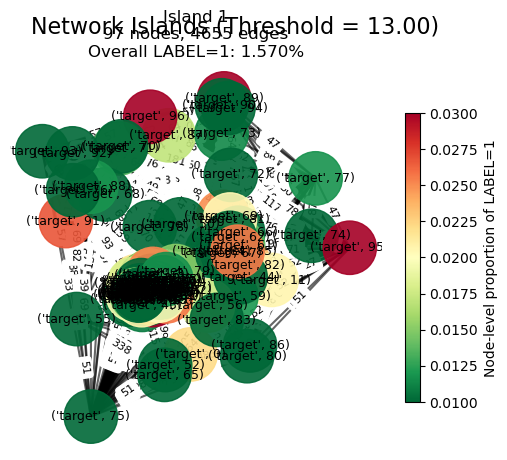

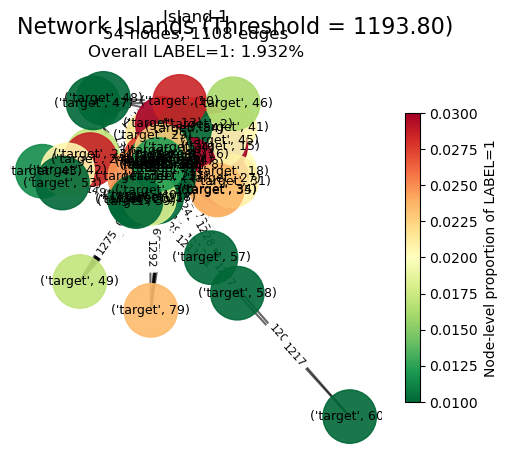

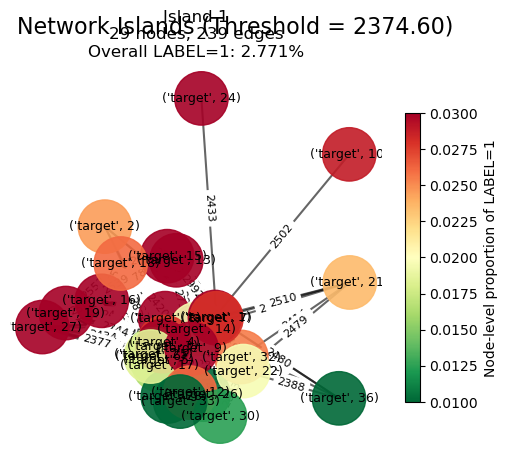

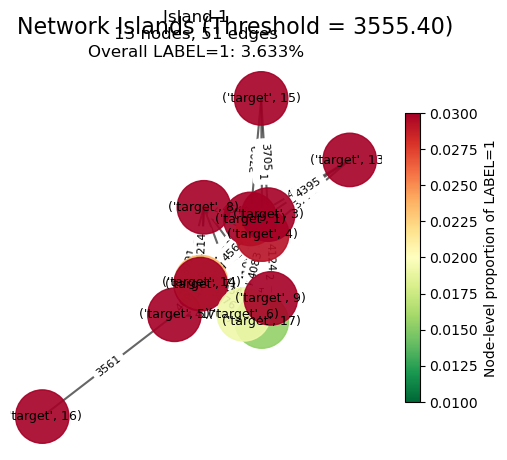

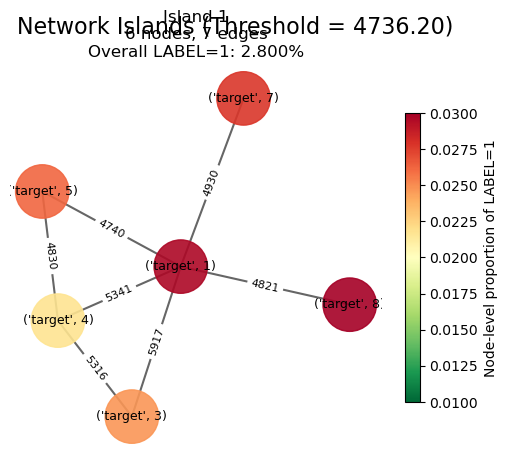

In [56]:
for threshold, graph in islands:

    visualise_islands(
        graph,
        threshold,
        min_nodes=2
    )

### **Dropout rate:** 
I was curious about how the drop out rate changes among the different classes, and among the reduced size islands. Of the ~170000 actions, there are only around ~4,000 drop outs, so its a really smaller percentage of total actions from the beginning. When we projected our bipartite network onto classes, we kept around the drop out label but redefined it as the number of the number of shared neighbour classes connected through edges where users dropped out of one of those classes.

The more central nodes have high drop out percentages (more red), because i set up the drop out label to count neighboring drop outs, so more central classes or ones with more shared users will be more likely to have more drop outs. 

- When looking at the whole network, we see a Drop out rate of 1.5%, this seems fairly low and acceptable for a general rate. 
- As we increase the threshold (and start to look at more popular classes) we start to see the dropout rate climb to 3.6% at the 3,555 threshold. Some possible explainations could be that these are the first or popular classes shown on the front of the website, so more people will take them even if they are not exactly what they are looking for leading to more dropouts, where the smaller classes might be more specific so less people take them, but those that do are more likely to stay?
- Finally at  our largest threshold 4736, only 6 classes make the cut, and our Drop out rate reduces back to 2.8% (still higher than the general popualtion, but less than the mid sized classes).

I wish I had the names of the classes in this dataset, it would be really cool to see related by subject matter the classes are. 